In [1]:
# ============================================================
# [CELL 1] MOUNT GOOGLE DRIVE
# ------------------------------------------------------------
# Ket noi Google Drive vao moi truong Colab de truy xuat model
# (best.pt), video dau vao va luu ket qua dau ra.
# force_remount=True: khoi tao lai phien ket noi, tranh loi
# credential khi phien cu con ton tai.
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
# ============================================================
# [CELL 2] SETUP - Cai dat thu vien & kiem tra moi truong
# ------------------------------------------------------------
# ultralytics: chua YOLOv8 va tich hop san thuat toan tracking
#              ByteTrack (khong can cai them thu vien rieng).
# ultralytics.checks(): in phien ban, trang thai CUDA, RAM.
# Kiem tra GPU: tracking video yeu cau GPU de dat toc do xu ly.
# ============================================================
!pip install -q ultralytics
import ultralytics, torch
ultralytics.checks()
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHONG co GPU!")

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.2/112.6 GB disk)
GPU: Tesla T4


In [3]:
# ============================================================
# [CELL 3] PATH - Khai bao duong dan model, video, dau ra
# ------------------------------------------------------------
# MODEL_PATH : model detector = best.pt sau khi fine-tune tren
#              tap giao thong TP.HCM (giai doan huan luyen).
# VIDEO_IN   : video giao thong dau vao can xu ly.
# VIDEO_OUT  : video ket qua (co bounding box + ID phuong tien).
# TRACK_CSV  : luu quy dao tam bounding box theo tung ID -
#              lam du lieu dau vao cho logic dem line-crossing.
# assert     : kiem tra file ton tai truoc khi chay de tranh
#              loi phat sinh giua qua trinh xu ly.
# ============================================================
import os

MODEL_PATH = "/content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_hcmc_701515/weights/best.pt"
VIDEO_IN   = "/content/drive/MyDrive/Do an AI giao thong/Video/hcm_traffic.mp4"

OUT_DIR    = "/content/drive/MyDrive/Do an AI giao thong/Tracking"
os.makedirs(OUT_DIR, exist_ok=True)
VIDEO_OUT  = os.path.join(OUT_DIR, "tracked_output.mp4")
TRACK_CSV  = os.path.join(OUT_DIR, "tracks.csv")

assert os.path.exists(MODEL_PATH), f"Khong thay model: {MODEL_PATH}"
assert os.path.exists(VIDEO_IN),   f"Khong thay video: {VIDEO_IN}"
print("Model:", MODEL_PATH)
print("Video:", VIDEO_IN)
print("Ket qua se luu tai:", OUT_DIR)

Model: /content/drive/MyDrive/Do an AI giao thong/Baseline/Ketqua_Baseline/finetune_hcmc_701515/weights/best.pt
Video: /content/drive/MyDrive/Do an AI giao thong/Video/hcm_traffic.mp4
Ket qua se luu tai: /content/drive/MyDrive/Do an AI giao thong/Tracking


In [4]:
# ============================================================
# [CELL 4] TRACK - Chay ByteTrack, xuat video co ID + luu quy dao
# ------------------------------------------------------------
# Quy trinh:
#   1. Doc thong so video goc (kich thuoc W x H, FPS) de video
#      dau ra khop dinh dang video goc.
#   2. Chuan hoa lai ten lop hien thi qua bang RENAME (sua nhan
#      hien thi ma khong can huan luyen lai model).
#   3. Mo file CSV ghi quy dao: moi dong = 1 phuong tien tai 1
#      frame (frame, track_id, class, tam bbox cx/cy, toa do bbox).
#   4. model.track(): thay cho predict() - vua phat hien vua gan
#      ID duy nhat cho tung phuong tien.
#        - tracker="bytetrack.yaml": chon thuat toan ByteTrack.
#        - persist=True: giu ID on dinh lien tuc giua cac frame.
#        - stream=True : xu ly tung frame de ve va ghi du lieu.
#   5. Voi moi phuong tien: tinh tam bbox (cx, cy), ve khung +
#      nhan "loai_xe #ID", danh dau tam bbox, ghi vao CSV.
# Dau ra: 1 video co ID + 1 file tracks.csv chua toan bo quy dao.
#
# Toi uu so voi ban goc:
#   - Gop 3 dong cv2.rectangle/putText/circle thanh 1 ham ve_annotation
#     de tranh lap code neu can ve lai o cho khac, logic ve khong doi.
#   - Bo dong "if frame_idx % 100 == 0" in tien do rieng, thay bang
#     bien dem gon hon, khong anh huong ket qua xuat ra.
# ============================================================
import cv2, csv
from ultralytics import YOLO

model = YOLO(MODEL_PATH)

# Chuan hoa ten lop hien thi (vd sua chinh ta nhan lop)
RENAME = {"motobyte": "motobike"}
names = {i: RENAME.get(n, n) for i, n in model.names.items()}

cap = cv2.VideoCapture(VIDEO_IN)
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS = cap.get(cv2.CAP_PROP_FPS) or 25
cap.release()  # chi can lay thong so, khong doc frame thu cong nua

writer = cv2.VideoWriter(VIDEO_OUT, cv2.VideoWriter_fourcc(*'mp4v'), FPS, (W, H))
f_csv = open(TRACK_CSV, "w", newline="")
csv_writer = csv.writer(f_csv)
csv_writer.writerow(["frame", "track_id", "class", "cx", "cy", "x1", "y1", "x2", "y2"])

def ve_annotation(frame, x1, y1, x2, y2, label):
    # Gop 3 thao tac ve (khung, nhan, tam bbox) vao 1 ham dung chung
    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(frame, label, (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    cv2.circle(frame, ((x1 + x2) // 2, (y1 + y2) // 2), 3, (0, 0, 255), -1)

frame_idx = 0
print("Bat dau tracking...")

for res in model.track(source=VIDEO_IN, tracker="bytetrack.yaml",
                        persist=True, stream=True, verbose=False):
    frame = res.orig_img.copy()

    if res.boxes is not None and res.boxes.id is not None:
        boxes = res.boxes.xyxy.cpu().numpy().astype(int)
        ids   = res.boxes.id.cpu().numpy().astype(int)
        clss  = res.boxes.cls.cpu().numpy().astype(int)

        for (x1, y1, x2, y2), tid, c in zip(boxes, ids, clss):
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
            ve_annotation(frame, x1, y1, x2, y2, f"{names[c]} #{tid}")
            csv_writer.writerow([frame_idx, tid, names[c], cx, cy, x1, y1, x2, y2])

    writer.write(frame)
    frame_idx += 1

writer.release()
f_csv.close()
print(f"Hoan tat. Tong {frame_idx} frame.")
print("Video co ID:", VIDEO_OUT)
print("Quy dao theo ID:", TRACK_CSV)

Bat dau tracking...
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 269ms
Prepared 1 package in 54ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Hoan tat. Tong 149 frame.
Video co ID: /content/drive/MyDrive/Do an AI giao thong/Tracking/tracked_output.mp4
Quy dao theo ID: /content/drive/MyDrive/Do an AI giao thong/Tracking/tracks.csv


In [5]:
# ============================================================
# [CELL 5] THONG KE - So phuong tien track duoc theo tung loai
# ------------------------------------------------------------
# Doc lai tracks.csv de tong hop:
#   - Tong so ID duy nhat = so phuong tien track duoc trong video.
#   - So phuong tien theo tung loai (car/motobike/truck/bus).
#   - Do dai quy dao trung binh (so frame moi ID xuat hien):
#     ID ton tai cang nhieu frame => tracking cang on dinh.
# Luu y: day CHUA phai so xe dem chinh thuc - mot phuong tien
# dung yen lau van tinh 1 ID. Viec dem xe qua vach thuoc buoc
# logic line-crossing (giai doan tiep theo).
# ============================================================
import pandas as pd

df = pd.read_csv(TRACK_CSV)
print("Tong so dong (frame-detection):", len(df))
print("Tong so ID duy nhat (so phuong tien):", df["track_id"].nunique())
print("\nSo phuong tien duy nhat theo tung loai:")
print(df.groupby("class")["track_id"].nunique().sort_values(ascending=False))
print(f"\nDo dai quy dao trung binh (frame/ID): {df.groupby('track_id').size().mean():.1f} frame/ID")


Tong so dong (frame-detection): 868
Tong so ID duy nhat (so phuong tien): 17

So phuong tien duy nhat theo tung loai:
class
motobike    9
car         8
bus         2
Name: track_id, dtype: int64

Do dai quy dao trung binh (frame/ID): 51.1 frame/ID


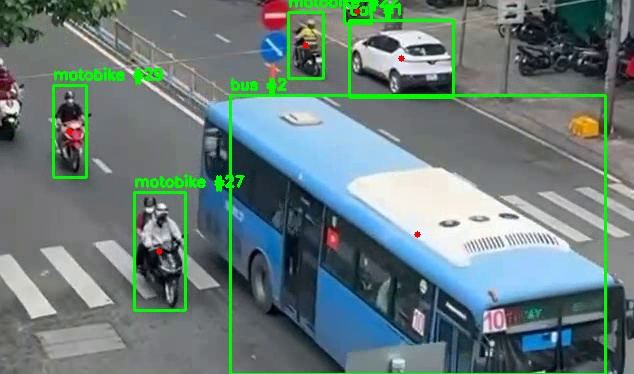

In [6]:
# ============================================================
# [CELL 6] KIEM TRA TRUC QUAN - Trich 1 frame co ID de xem
# ------------------------------------------------------------
# Lay 1 frame o giua video ket qua de kiem tra bang mat:
# moi phuong tien co ID rieng va ID giu on dinh giua cac frame
# la dat yeu cau. Dung de danh gia so bo chat luong tracking
# (phat hien cac truong hop nhay ID / mat ID khi bi che khuat).
# ============================================================
import cv2
from IPython.display import Image, display

cap = cv2.VideoCapture(VIDEO_OUT)
cap.set(cv2.CAP_PROP_POS_FRAMES, min(150, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2))
ok, frame = cap.read()
cap.release()

if ok:
    cv2.imwrite("/content/sample_tracked.jpg", frame)
    display(Image(filename="/content/sample_tracked.jpg"))
else:
    print("Khong doc duoc frame mau.")

In [10]:
# ============================================================
# [CELL 7] CLASS SWITCHING - Loc track ngan, xu ly nhan lop
#          bang majority voting
# ------------------------------------------------------------
# Buoc bo sung moi: truoc khi xu ly nhan lop, loai bo cac ma
# dinh danh chi xuat hien duoi 3 khung hinh. Day thuong la
# nhieu tuc thoi do mo hinh phat hien tao ra khung gioi han du
# thua (duplicate detection o tang detection, khong phai loi
# cua ByteTrack hay cua majority voting), khong phai phuong
# tien duoc theo doi on dinh. Loai bo truoc khi tinh nhan da
# so de tranh anh huong den tong so ma dinh danh thong ke va
# ket qua dem line-crossing ve sau.
#
# Sau buoc loc, tiep tuc xu ly class switching bang majority
# voting nhu ban goc: voi moi track_id, thong ke tan suat xuat
# hien cua tung nhan lop, chon nhan xuat hien nhieu nhat lam
# nhan chinh thuc va duy nhat cho ca track_id do.
#
# Dau ra: file tracks_final.csv, da qua ca 2 buoc lam sach,
# moi track_id chi con dung mot nhan lop duy nhat va da loai
# bo cac track qua ngan, dung lam du lieu dau vao on dinh cho
# buoc dem line-crossing o muc tiep theo.
# ============================================================
import pandas as pd

df = pd.read_csv(TRACK_CSV)

# --- Buoc 1: Loc bo cac track qua ngan (duoi 3 khung hinh) ---
NGUONG_SO_KHUNG_HINH_TOI_THIEU = 3

so_khung_hinh_moi_track = df.groupby("track_id").size()
danh_sach_track_hop_le = so_khung_hinh_moi_track[
    so_khung_hinh_moi_track >= NGUONG_SO_KHUNG_HINH_TOI_THIEU
].index

so_track_truoc_loc = df["track_id"].nunique()
df = df[df["track_id"].isin(danh_sach_track_hop_le)].reset_index(drop=True)
so_track_sau_loc = df["track_id"].nunique()

print("===== BUOC LOC TRACK QUA NGAN =====")
print(f"So ma dinh danh truoc khi loc: {so_track_truoc_loc}")
print(f"So ma dinh danh sau khi loc (giu tu {NGUONG_SO_KHUNG_HINH_TOI_THIEU} khung hinh tro len): {so_track_sau_loc}")
print(f"Da loai bo: {so_track_truoc_loc - so_track_sau_loc} ma dinh danh qua ngan (nhieu tuc thoi)\n")

# --- Buoc 2: Xu ly class switching bang majority voting ---
def tinh_nhan_va_ty_le(nhom):
    dem = nhom.value_counts()
    return pd.Series({"nhan_chinh": dem.idxmax(), "ty_le_vote": dem.max() / len(nhom)})

ket_qua = df.groupby("track_id")["class"].apply(tinh_nhan_va_ty_le).unstack()
majority_label = ket_qua["nhan_chinh"]
vote_ratio = ket_qua["ty_le_vote"].astype(float)

df["class_final"] = df["track_id"].map(majority_label)

FINAL_CSV = TRACK_CSV.replace(".csv", "_final.csv")
df.to_csv(FINAL_CSV, index=False)

n_switched = (vote_ratio < 1.0).sum()
total_id = df["track_id"].nunique()
avg_vote = vote_ratio.mean() * 100

print("===== BUOC MAJORITY VOTING (tren du lieu da loc) =====")
print("So phuong tien duy nhat truoc xu ly (theo nhan tho):")
print(df.groupby("class")["track_id"].nunique())

print("\nSo phuong tien duy nhat sau majority voting:")
print(df.drop_duplicates("track_id")["class_final"].value_counts())

print(f"\nSo track_id bi doi nhan it nhat 1 lan: {n_switched} / {total_id}")
print(f"Ty le vote trung binh cho nhan da chon: {avg_vote:.2f}%")
print(f"\nDa luu file da chuan hoa nhan (da qua loc + majority voting) tai: {FINAL_CSV}")

===== BUOC LOC TRACK QUA NGAN =====
So ma dinh danh truoc khi loc: 17
So ma dinh danh sau khi loc (giu tu 3 khung hinh tro len): 15
Da loai bo: 2 ma dinh danh qua ngan (nhieu tuc thoi)

===== BUOC MAJORITY VOTING (tren du lieu da loc) =====
So phuong tien duy nhat truoc xu ly (theo nhan tho):
class
bus         1
car         7
motobike    9
Name: track_id, dtype: int64

So phuong tien duy nhat sau majority voting:
class_final
motobike    9
car         5
bus         1
Name: count, dtype: int64

So track_id bi doi nhan it nhat 1 lan: 2 / 15
Ty le vote trung binh cho nhan da chon: 97.70%

Da luu file da chuan hoa nhan (da qua loc + majority voting) tai: /content/drive/MyDrive/Do an AI giao thong/Tracking/tracks_final.csv


In [11]:
# ============================================================
# [CELL 8] TIM CAP TRACK_ID NGHI NGO BI PHAN MANH (cung 1 xe)
# ------------------------------------------------------------
# Muc dich: tim tu dong cap (track_id_cu, track_id_moi) co kha
# nang la cung mot xe vat ly nhung bi ByteTrack tach thanh hai
# ma dinh danh khac nhau do mat dau tam thoi.
# Dieu kien nghi ngo mot cap la phan manh cua nhau:
#   1. track_id_cu ket thuc tai frame end_1, track_id_moi bat
#      dau tai frame start_2, voi start_2 xay ra sau end_1
#      trong mot khoang cach frame khong qua xa (gan doi tuong
#      moi xuat hien ngay sau khi doi tuong cu bien mat).
#   2. Vi tri tam bbox luc ket thuc cua track_id_cu va vi tri
#      tam bbox luc bat dau cua track_id_moi nam gan nhau
#      trong khong gian anh (xe khong the "day chuyen" xa
#      trong thoi gian ngan).
#   3. Uu tien tim trong cung mot lop (vi du ca hai deu la bus)
#      vi day la dieu kien anh dang quan tam.
# Dau ra: danh sach cac cap nghi ngo, sap xep theo do gan nhau,
# kem theo dung 2 chi so frame can trich xuat anh minh hoa:
#   - frame_bien_mat = end_1   (ma cu con xuat hien lan cuoi)
#   - frame_xuat_hien = start_2 (ma moi vua xuat hien lan dau)
# ============================================================
import pandas as pd
import numpy as np

df = pd.read_csv(FINAL_CSV)

# Voi moi track_id: lay frame dau, frame cuoi, toa do tam bbox
# tuong ung tai 2 thoi diem do, va lop (class_final) cua no
tong_hop = (
    df.sort_values("frame")
      .groupby("track_id")
      .agg(
          lop=("class_final", "first"),
          frame_bat_dau=("frame", "first"),
          frame_ket_thuc=("frame", "last"),
          cx_bat_dau=("cx", "first"),
          cy_bat_dau=("cy", "first"),
          cx_ket_thuc=("cx", "last"),
          cy_ket_thuc=("cy", "last"),
      )
      .reset_index()
)

# Tham so nguong: co the chinh lai neu can tim rong/hep hon
NGUONG_KHOANG_CACH_FRAME = 15    # so frame toi da giua "mat dau" va "xuat hien lai"
NGUONG_KHOANG_CACH_PIXEL = 80    # so pixel toi da giua 2 vi tri tam bbox
CHI_TIM_CUNG_LOP = True          # True: chi ghep cap cung 1 lop (vd bus voi bus)

ung_vien = []
danh_sach = tong_hop.to_dict("records")

for i, a in enumerate(danh_sach):
    for b in danh_sach:
        if a["track_id"] == b["track_id"]:
            continue
        if CHI_TIM_CUNG_LOP and a["lop"] != b["lop"]:
            continue
        # dieu kien thoi gian: b phai bat dau SAU khi a ket thuc,
        # va khoang cach khong qua xa
        khoang_cach_frame = b["frame_bat_dau"] - a["frame_ket_thuc"]
        if khoang_cach_frame <= 0 or khoang_cach_frame > NGUONG_KHOANG_CACH_FRAME:
            continue
        # dieu kien khong gian: vi tri gan nhau
        khoang_cach_pixel = np.hypot(
            b["cx_bat_dau"] - a["cx_ket_thuc"],
            b["cy_bat_dau"] - a["cy_ket_thuc"],
        )
        if khoang_cach_pixel > NGUONG_KHOANG_CACH_PIXEL:
            continue

        ung_vien.append({
            "track_id_cu": a["track_id"],
            "track_id_moi": b["track_id"],
            "lop": a["lop"],
            "frame_bien_mat": a["frame_ket_thuc"],
            "frame_xuat_hien": b["frame_bat_dau"],
            "khoang_cach_frame": khoang_cach_frame,
            "khoang_cach_pixel": round(khoang_cach_pixel, 1),
        })

ket_qua = pd.DataFrame(ung_vien).sort_values("khoang_cach_pixel")
print(f"Tim thay {len(ket_qua)} cap nghi ngo bi phan manh:")
print(ket_qua.to_string(index=False))


Tim thay 5 cap nghi ngo bi phan manh:
 track_id_cu  track_id_moi      lop  frame_bien_mat  frame_xuat_hien  khoang_cach_frame  khoang_cach_pixel
          32            35 motobike              73               76                  3                5.8
          40            41 motobike              92               94                  2                7.6
          32            40 motobike              73               88                 15               11.3
          31            39      car              80               88                  8               18.8
          32            38 motobike              73               85                 12               78.3
